# Exp 12: pre-saturation inefficient regime on designed instances


In [1]:
from pathlib import Path
import gzip
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

In [2]:
FIG_DIR = Path("../figures/exp_12")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Light-mode chart tokens
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRID = "#e1e0d9"
AXIS = "#c3c2b7"
BLUE = "#2a78d6"

# Match-state colors for the ε_h strips
MATCH_NONE = GRID          # no high type matched
MATCH_SOME = "#86b6ef"     # some but not all high types matched
MATCH_ALL = "#184f95"      # all high types matched
PREDICTED_FILL = "#ecebe7" # predicted window, as context

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "text.color": INK,
    "axes.labelcolor": INK_SECONDARY,
    "axes.edgecolor": AXIS,
    "axes.linewidth": 0.8,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "xtick.labelcolor": INK_SECONDARY,
    "ytick.labelcolor": INK_SECONDARY,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "grid.color": GRID,
    "grid.linewidth": 0.8,
    "legend.frameon": False,
})


def save(fig, name):
    fig.savefig(FIG_DIR / name, bbox_inches="tight", dpi=300)
    plt.show()

In [3]:
def load_payload(file):
    with gzip.open(file, "rt", encoding="utf-8") as f:
        return json.load(f)


def window_row(payload):
    return {"instance": payload["instance_id"], "job_id": payload["job_id"], **payload["window"]}


def point_rows(payload):
    high_ids = set(payload["high_ids"])
    for run in payload["runs"]:
        summary = run["summary"]
        primary = summary["platform_solve_result"]["primary_result"]
        matched = set(primary["selected_intermediaries"])
        yield {
            "instance": payload["instance_id"],
            "eps_h": run["eps_h"],
            "phase": run["phase"].split("_")[0],
            "n_high": len(matched & high_ids),
            "n_low": len(matched - high_ids),
            "platform_profit": primary["platform_profit"],
            "rel_gap": summary["rel_gap"],
            "time": summary["total_time"],
        }

In [4]:
payloads = [load_payload(f) for f in sorted(Path("../results/exp_12").rglob("*.json.gz"))]


def decode(value):
    # utils.encode_nonfinite saves NaN and ±inf as strings (e.g. eps_h_bar = "Infinity", regime_sat = "NaN")
    return float(value) if value in ("NaN", "Infinity", "-Infinity") else value


windows = pd.DataFrame([{k: decode(v) for k, v in window_row(p).items()} for p in payloads])
windows = windows.set_index("instance").sort_index()

points = pd.DataFrame([row for p in payloads for row in point_rows(p)])
points = points.sort_values(["instance", "eps_h"]).reset_index(drop=True)
points = points.join(windows[["T_h", "L", "eps_h_minus", "eps_h_plus", "eps_h_bar"]], on="instance")
points["match_rate"] = points["n_high"] / points["T_h"]

# every job sweeps the coarse grid up to L + 1, so each sweep should reach it
reach = points.groupby("instance")["eps_h"].max()
incomplete = sorted(reach.index[reach < windows["L"] + 1 - 1e-9])
print(f"{len(windows)} instances (jobs {windows['job_id'].min()}-{windows['job_id'].max()}), {len(points)} solved points")
print(f"runs per job: {points.groupby('instance').size().min()}-{points.groupby('instance').size().max()}; "
      f"sweeps that stop before L + 1: {incomplete or 'none'}")
print(f"max solver rel_gap: {points['rel_gap'].max():.1e}")

# jobs whose bisection hasn't finished (still running, or stopped): brackets wider than JUMP_TOL whose matchings differ.
# Results for these instances are provisional; exp_12.py resumes from the saved runs if a job needs restarting.
JUMP_TOL = payloads[0]["experiment_metadata"]["constants"]["jump_tol"]


def signature(r):
    return (r.n_high, r.n_low)


unresolved = {}
for p in payloads:
    g = points.query("instance == @p['instance_id']")
    rows = list(g.itertuples())
    wide = [(a.eps_h, b.eps_h) for a, b in zip(rows, rows[1:])
            if b.eps_h - a.eps_h > JUMP_TOL + 1e-9 and signature(a) != signature(b)]
    if wide:
        unresolved[p["job_id"]] = (p["instance_id"], wide)
print(f"jobs with unresolved switch brackets (> {JUMP_TOL}), provisional: {len(unresolved)}")
for job, (i, wide) in sorted(unresolved.items()):
    print(f"  job {job} (#{i}): " + ", ".join(f"({a:.3f}, {b:.3f}]" for a, b in wide))

32 instances (jobs 0-31), 1346 solved points
runs per job: 35-50; sweeps that stop before L + 1: none
max solver rel_gap: 9.6e-05
jobs with unresolved switch brackets (> 0.025), provisional: 0


In [5]:
# the compact_window_instances.csv row, as saved in each job payload
params = windows

PARAM_COLS = ["K", "n_h", "n_l", "eps_l", "T_h", "T_l", "rho"]
PARAM_LABELS = {"K": "K", "n_h": "n_h", "n_l": "n_ℓ", "eps_l": "ε_ℓ", "T_h": "T_h", "T_l": "T_ℓ", "rho": "ρ"}

shape_cols = ["K", "n_h", "n_l", "T_h", "T_l"]
n_shapes = len(params[shape_cols].drop_duplicates())
n_distinct = len(params[PARAM_COLS].drop_duplicates())
print(f"{len(params)} instances")
print(f"{n_shapes} distinct (K, n_h, n_ℓ, T_h, T_ℓ) shapes")
print(f"{n_distinct} distinct once ε_ℓ and ρ are included")

print()
print(f"farmer_quantity: {sorted(params['farmer_quantity'].unique())}")
print(f"Assumption 1 relaxed: {params['relaxed'].fillna('none').value_counts().to_dict()}")
print(f"LP-verified designs: {int(params['lp_verified'].sum())} / {len(params)}; "
      f"min |profit margin| {params['lp_min_abs_margin'].min():.3g}, min relative margin {params['lp_rel_margin'].min():.3g}")
print(f"saturated behaviour (CSV): {params['sat_behavior'].value_counts().to_dict()}")
print(f"finite ε̄_h: {np.isfinite(params['eps_h_bar']).sum()} / {len(params)}")

32 instances
19 distinct (K, n_h, n_ℓ, T_h, T_ℓ) shapes
32 distinct once ε_ℓ and ρ are included

farmer_quantity: [np.int64(1)]
Assumption 1 relaxed: {'F_div_K': 32}
LP-verified designs: 32 / 32; min |profit margin| 0.02, min relative margin 0.169
saturated behaviour (CSV): {'none': 25, 'ineff_immediately': 6, 'eff': 1}
finite ε̄_h: 25 / 32


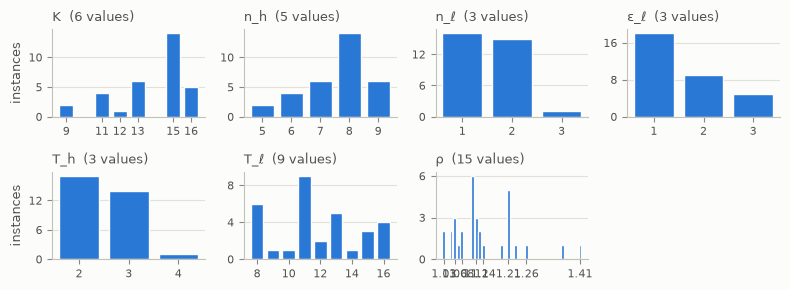

In [6]:
def plot_value_counts(ax, values):
    counts = values.value_counts().sort_index()
    step = np.diff(counts.index).min() if len(counts) > 1 else 1
    ax.bar(counts.index, counts.values, width=0.8 * step, color=BLUE, edgecolor=SURFACE, linewidth=1)

    ticks = counts.index[::2] if len(counts) > 8 else counts.index
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{v:g}" for v in ticks])


fig, axes = plt.subplots(2, 4, figsize=(8, 3))
for ax, col in zip(axes.flat, PARAM_COLS):
    plot_value_counts(ax, params[col])
    ax.set_title(f"{PARAM_LABELS[col]}  ({params[col].nunique()} values)", loc="left", color=INK_SECONDARY)
    ax.grid(axis="y")
    ax.set_axisbelow(True)
    ax.yaxis.set_major_locator(plt.MaxNLocator(3, integer=True))

for ax in axes.flat[len(PARAM_COLS):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("instances")

fig.tight_layout()
save(fig, "param_distributions.png")

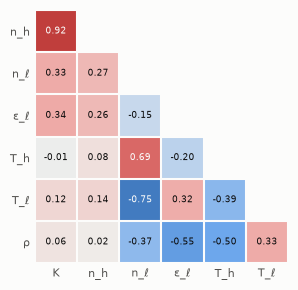

In [7]:
corr = params[PARAM_COLS].corr(method="spearman")

# Keep the strict lower triangle only: drop the first row and last column, then mask the upper part
lower = corr.iloc[1:, :-1]
lower = lower.where(np.tril(np.ones(lower.shape, dtype=bool)))

diverging = LinearSegmentedColormap.from_list(
    "blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ee8a87", "#b8302f"]
)

fig, ax = plt.subplots(figsize=(4, 3))
ax.imshow(lower.to_numpy(), cmap=diverging, vmin=-1, vmax=1, interpolation="nearest")

for i in range(lower.shape[0]):
    for j in range(i + 1):
        r = lower.iat[i, j]
        text_color = SURFACE if abs(r) > 0.65 else INK
        ax.text(j, i, f"{r:.2f}", ha="center", va="center", fontsize=6.5, color=text_color)

# White gutters between cells
ax.set_xticks(np.arange(lower.shape[1] + 1) - 0.5, minor=True)
ax.set_yticks(np.arange(lower.shape[0] + 1) - 0.5, minor=True)
ax.grid(which="minor", color=SURFACE, linewidth=1.5)
ax.tick_params(which="both", length=0)

ax.set_xticks(range(lower.shape[1]))
ax.set_xticklabels([PARAM_LABELS[c] for c in lower.columns])
ax.set_yticks(range(lower.shape[0]))
ax.set_yticklabels([PARAM_LABELS[c] for c in lower.index])
for spine in ax.spines.values():
    spine.set_visible(False)

fig.tight_layout()
save(fig, "param_correlation.png")

In [8]:
def first_index(mask):
    idx = np.flatnonzero(mask)
    return idx[0] if len(idx) else None


def find_switches(eps, n_high, before_L, T_h):
    """Brackets for the onset and exit of the first inefficient run before L."""
    inefficient = before_L & (n_high > 0)
    k = first_index(inefficient)
    if k is None:
        return dict(onset_lo=np.nan, onset_hi=np.nan, full_onset=np.nan,
                    exit_lo=np.nan, exit_hi=np.nan, exit_censored=False)

    full = first_index(before_L & (n_high == T_h))

    # Walk to the end of the first inefficient run
    j = k
    while j + 1 < len(eps) and inefficient[j + 1]:
        j += 1
    has_next = j + 1 < len(eps)

    return dict(
        onset_lo=eps[k - 1] if k > 0 else np.nan,
        onset_hi=eps[k],
        full_onset=eps[full] if full is not None else np.nan,
        exit_lo=eps[j],
        exit_hi=eps[j + 1] if has_next else np.nan,
        exit_censored=not (has_next and before_L[j + 1]),
    )


def summarize_sweep(g, w):
    eps = g["eps_h"].to_numpy()
    n_high = g["n_high"].to_numpy()
    before_L = eps <= w["L"] + 1e-9

    row = find_switches(eps, n_high, before_L, w["T_h"])

    is_inefficient = (n_high[before_L] > 0).astype(int)
    row["n_switches_le_L"] = int(np.abs(np.diff(is_inefficient)).sum())
    row["partial_levels"] = sorted(set(n_high.tolist()) - {0, w["T_h"]})

    # Saturated regime: first switch to matching high types above L (bracket only if the point before is efficient)
    above_L = ~before_L
    k_sat = first_index(above_L & (n_high > 0))
    has_bracket = k_sat is not None and k_sat > 0 and n_high[k_sat - 1] == 0
    row["sat_onset_lo"] = eps[k_sat - 1] if has_bracket else np.nan
    row["sat_onset_hi"] = eps[k_sat] if has_bracket else np.nan
    row["matched_above_L"] = bool((n_high[above_L] > 0).any())
    is_inefficient_above = (n_high[above_L] > 0).astype(int)
    row["n_switches_gt_L"] = int(np.abs(np.diff(is_inefficient_above)).sum())

    # Inside the observed window, does the matched set have the predicted counts?
    inside = g[before_L & (n_high > 0)]
    if len(inside):
        predicted = (inside["n_high"] == w["matched_high_in_window"]) & (inside["n_low"] == w["matched_low_in_window"])
        row["exact_set_share"] = predicted.mean()
    else:
        row["exact_set_share"] = np.nan
    return row

In [9]:
switches = pd.DataFrame({
    instance_id: summarize_sweep(g, windows.loc[instance_id])
    for instance_id, g in points.groupby("instance")
}).T
switches.index.name = "instance"
switches = switches.infer_objects()
switches = switches.join(windows[["K", "T_h", "T_l", "n_h", "rho", "L", "eps_h_minus", "eps_h_plus", "eps_h_bar",
                                  "sat_behavior", "lp_min_abs_margin", "lp_rel_margin", "relaxed"]])

switches["onset_mid"] = (switches["onset_lo"] + switches["onset_hi"]) / 2
switches["exit_mid"] = (switches["exit_lo"] + switches["exit_hi"]) / 2
switches["onset_offset"] = switches["onset_mid"] - switches["eps_h_minus"]
# Censored exits: only the last inefficient point is known, so this is a lower bound
switches["exit_offset"] = np.where(
    switches["exit_censored"],
    switches["exit_lo"] - switches["eps_h_plus"],
    switches["exit_mid"] - switches["eps_h_plus"],
)
switches["sat_onset_offset"] = (switches["sat_onset_lo"] + switches["sat_onset_hi"]) / 2 - switches["eps_h_bar"]
switches["sat_onset_contains_bar"] = (switches["sat_onset_lo"] <= switches["eps_h_bar"] + 1e-6) & (
    switches["eps_h_bar"] <= switches["sat_onset_hi"] + 1e-6)

In [10]:
n = len(switches)
early = switches["onset_hi"] < switches["eps_h_minus"]  # whole onset bracket below ε_h⁻
late = switches["exit_lo"] > switches["eps_h_plus"]     # still inefficient past ε_h⁺
censored = switches["exit_censored"]
n_switches = switches["n_switches_le_L"]
has_partial = switches["partial_levels"].str.len() > 0


def describe(s):
    return f"median {s.median():+.2f}, range [{s.min():+.2f}, {s.max():+.2f}]"


print("Observed windows")
print(f"  with an inefficient window:     {switches['onset_hi'].notna().sum()} / {n}")
print(f"  one clean window (uncensored):  {(n_switches == 2).sum()}")
print(f"  one window, censored at L:      {(n_switches == 1).sum()}")
print(f"  with re-entries:                {(n_switches > 2).sum()}")
print()
print("Timing vs. prediction")
print(f"  onset strictly before ε_h⁻:     {early.sum()} / {n}   (onset − ε_h⁻: {describe(switches['onset_offset'])})")
print(f"  exit strictly after ε_h⁺:       {late.sum()} / {n}")
print(f"  uncensored exit − ε_h⁺:         {describe(switches.loc[~censored, 'exit_offset'])}")
print()
print("Matched set")
print(f"  instances with partial matching: {has_partial.sum()}  {sorted(switches.index[has_partial])}")
print(f"  inside window, predicted counts: {switches['exact_set_share'].mean():.1%} of points on average")
print()
print("Saturated regime (L, L + 1]")
sweep_end = points.groupby("instance")["eps_h"].max()
bar_in_sweep = np.isfinite(switches["eps_h_bar"]) & (switches["eps_h_bar"] < sweep_end)
sat = switches[bar_in_sweep]
print(f"  ε̄_h inside the sweep:           {bar_in_sweep.sum()} / {n}")
print(f"  of those, observed sat. onset:  {sat['sat_onset_hi'].notna().sum()}; bracket contains ε̄_h: {int(sat['sat_onset_contains_bar'].sum())}")
print(f"  sat. onset − ε̄_h:               {describe(sat['sat_onset_offset'].dropna())}")
print(f"  ε̄_h = ∞ but high types matched above L: {sorted(switches.index[~np.isfinite(switches['eps_h_bar']) & switches['matched_above_L']])}")
print(f"  switch back to efficient above L: {sorted(switches.index[switches['n_switches_gt_L'] >= 2])}")
print()
print("Sweep resolution")
print(f"  widest onset bracket: {(switches['onset_hi'] - switches['onset_lo']).max():.3f}")
print(f"  widest exit bracket:  {(switches['exit_hi'] - switches['exit_lo']).max():.3f}")

Observed windows
  with an inefficient window:     32 / 32
  one clean window (uncensored):  22
  one window, censored at L:      8
  with re-entries:                2

Timing vs. prediction
  onset strictly before ε_h⁻:     32 / 32   (onset − ε_h⁻: median -0.53, range [-1.60, -0.09])
  exit strictly after ε_h⁺:       28 / 32
  uncensored exit − ε_h⁺:         median +0.09, range [-3.29, +0.23]

Matched set
  instances with partial matching: 10  [5, 6, 7, 9, 12, 13, 16, 17, 23, 31]
  inside window, predicted counts: 92.9% of points on average

Saturated regime (L, L + 1]
  ε̄_h inside the sweep:           25 / 32
  of those, observed sat. onset:  16; bracket contains ε̄_h: 2
  sat. onset − ε̄_h:               median +0.02, range [-0.09, +0.28]
  ε̄_h = ∞ but high types matched above L: [11, 12, 29]
  switch back to efficient above L: [1]

Sweep resolution
  widest onset bracket: 0.025
  widest exit bracket:  0.100


In [11]:
def match_color(n_high, T_h):
    if n_high == 0:
        return MATCH_NONE
    return MATCH_ALL if n_high == T_h else MATCH_SOME


def draw_instance_row(ax, y, g, w, strip_h=0.56, box_h=0.8):
    # Observed match state: one cell per solved point, edges at midpoints between points
    eps = g["eps_h"].to_numpy()
    edges = np.concatenate([[eps[0]], (eps[1:] + eps[:-1]) / 2, [eps[-1]]])
    for x0, x1, n_high in zip(edges[:-1], edges[1:], g["n_high"]):
        ax.add_patch(Rectangle((x0, y - strip_h / 2), x1 - x0, strip_h,
                               facecolor=match_color(n_high, w["T_h"]), edgecolor="none"))

    # Predicted window, truncated at L
    lo, hi = w["eps_h_minus"], min(w["eps_h_plus"], w["L"])
    ax.add_patch(Rectangle((lo, y - box_h / 2), hi - lo, box_h,
                           facecolor="none", edgecolor=INK, linewidth=0.9))
    # Predicted saturated inefficient region (ε̄_h, ∞), when finite
    if np.isfinite(w["eps_h_bar"]) and w["eps_h_bar"] < eps[-1]:
        lo = max(w["eps_h_bar"], w["L"])
        ax.add_patch(Rectangle((lo, y - box_h / 2), eps[-1] - lo, box_h,
                               facecolor="none", edgecolor=INK, linewidth=0.9))
    ax.plot([w["L"], w["L"]], [y - box_h / 2, y + box_h / 2], color=INK_SECONDARY, linewidth=1.2)


def row_label(instance_id):
    w = windows.loc[instance_id]
    return f"#{instance_id}  K={w['K']}, T_h={w['T_h']}, ρ={w['rho']:g}"


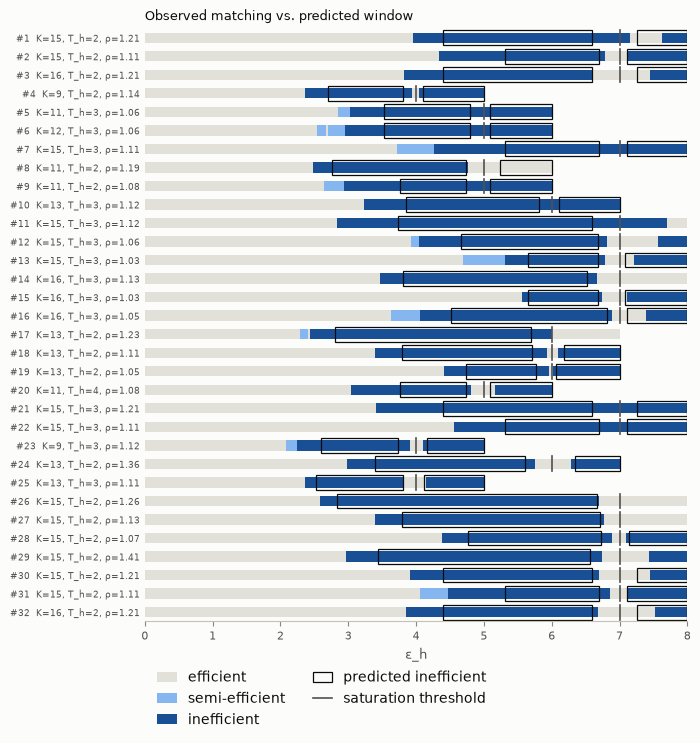

In [12]:
order = switches.index.tolist()

fig, ax = plt.subplots(figsize=(7, 0.2 * len(order) + 1.3))
for y, instance_id in enumerate(order):
    draw_instance_row(ax, y, points.query("instance == @instance_id"), windows.loc[instance_id])

ax.set_xlim(0, points["eps_h"].max())
ax.set_ylim(len(order) - 0.5, -0.5)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([row_label(i) for i in order], fontsize=6.5)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("ε_h")
ax.set_title("Observed matching vs. predicted window", loc="left", color=INK)

legend_handles = [
    Patch(facecolor=MATCH_NONE, label="efficient"),
    Patch(facecolor=MATCH_SOME, label="semi-efficient"),
    Patch(facecolor=MATCH_ALL, label="inefficient"),
    Patch(facecolor="none", edgecolor=INK, linewidth=0.9, label="predicted inefficient"),
    Line2D([], [], color=INK_SECONDARY, linewidth=1.2, label="saturation threshold"),
]
ax.legend(handles=legend_handles, loc="upper left", bbox_to_anchor=(0, -0.045 * 44 / len(order)),
          ncol=2, handlelength=1.4)

save(fig, "window_overview.png")

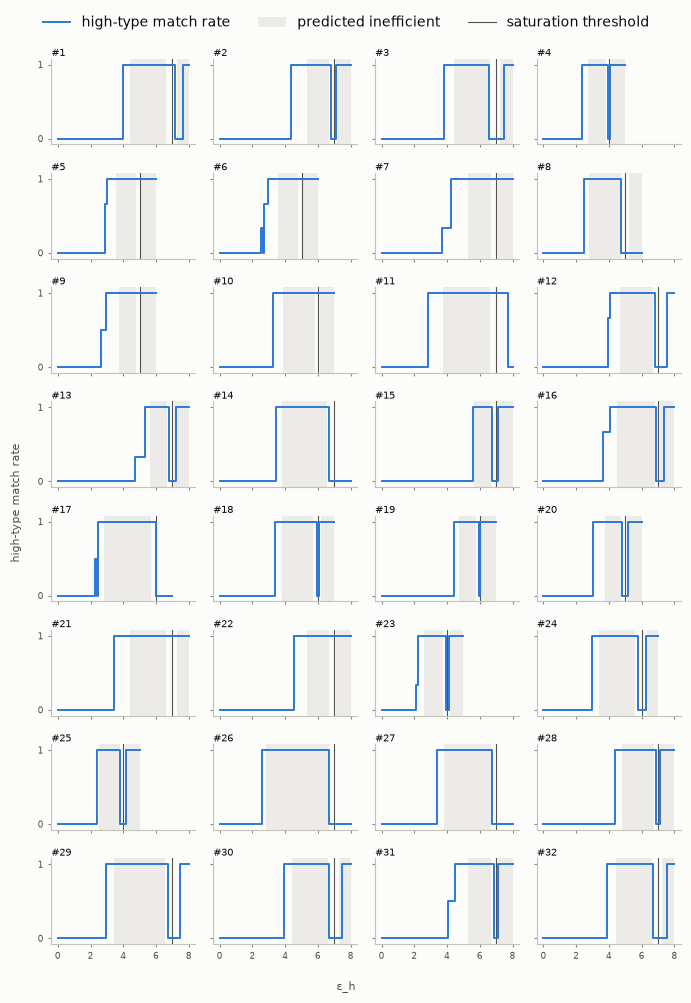

In [14]:
n_cols = 4
instance_ids = sorted(windows.index)
n_rows = int(np.ceil(len(instance_ids) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(1.75 * n_cols, 1.25 * n_rows),
                         sharex=True, sharey=True, squeeze=False)

for ax, instance_id in zip(axes.flat, instance_ids):
    w = windows.loc[instance_id]
    g = points.query("instance == @instance_id")

    ax.axvspan(w["eps_h_minus"], min(w["eps_h_plus"], w["L"]), color=PREDICTED_FILL, linewidth=0, zorder=0)
    if np.isfinite(w["eps_h_bar"]):
        ax.axvspan(max(w["eps_h_bar"], w["L"]), g["eps_h"].max(), color=PREDICTED_FILL, linewidth=0, zorder=0)
    ax.axvline(w["L"], color=INK_SECONDARY, linewidth=0.8, zorder=1)
    ax.step(g["eps_h"], g["match_rate"], where="mid", color=BLUE, linewidth=1.4, zorder=2)

    ax.set_title(f"#{instance_id}", loc="left", fontsize=7.5, color=INK, pad=2)
    ax.set_ylim(-0.08, 1.08)
    ax.set_yticks([0, 1])
    ax.tick_params(labelsize=6.5, length=2)

for ax in axes.flat[len(instance_ids):]:
    ax.set_visible(False)

fig.supxlabel("ε_h", fontsize=8, color=INK_SECONDARY)
fig.supylabel("high-type match rate", fontsize=8, color=INK_SECONDARY)
fig.legend(
    handles=[
        Line2D([], [], color=BLUE, linewidth=1.4, label="high-type match rate"),
        Patch(facecolor=PREDICTED_FILL, label="predicted inefficient"),
        Line2D([], [], color=INK_SECONDARY, linewidth=0.8, label="saturation threshold"),
    ],
    loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=3,
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "match_rate_eps_h_sweep_13.png")